<a href="https://colab.research.google.com/github/Perlangas28/Simulacion_2/blob/main/Modelo_SIR_con_Metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<hr style="border: 2px solid pink;">

# <font color="hotpink"> **Modelo SIR con Metrópolis**

**Alumna:** Perla Blancas Hernández

**Materia:** Investigación de Operaciones

**Maestro:** Ricardo Medel Esquivel

<hr style="border: 2px solid pink;">

##<font color= "lightpink"> **Ajuste de parámetros del modelo SIR mediante MCMC**

El artículo *The inverse problem of a dynamical system solved with genetic algorithms* (2021) presenta datos de influenza de un internado con \(N=763\) alumnos, recopilados en la Tabla 1 de la sección 2.2. Cada dato representa el número de personas infectadas en un día determinado, no los nuevos contagios diarios.

Se conocen las condiciones iniciales \(I(0)=1\) y \(N=763\). Al suponer que inicialmente no hay recuperados, \(R(0)=0\), se obtiene \(S(0)=762\). El objetivo es estimar los parámetros \(a\) y \(b\) del modelo SIR para que la trayectoria \(I(t;a,b)\) se ajuste a los datos observados.

Mientras que el artículo original utiliza un algoritmo genético y la distancia \(L_1\), en este trabajo se mantiene el modelo y los datos, pero se aplica un enfoque bayesiano mediante el algoritmo de Metropolis, siguiendo el tutorial *An Introduction to Markov Chain Monte Carlo*. La distribución del error y las distribuciones a priori se establecen para este análisis.

Versiones: {'Python': '3.13.16', 'NumPy': '2.1.3', 'SciPy': '1.16.3', 'ArviZ': '0.22.0'}


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Día,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Infectados observados,1,3,6,25,73,222,294,258,237,191,125,69,27,11,4


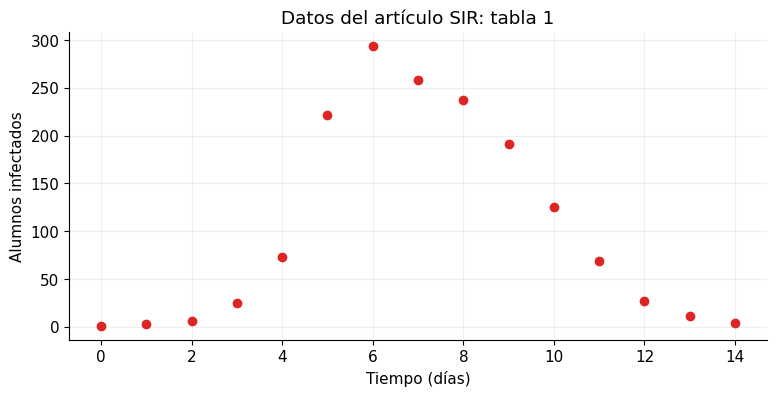

In [1]:
import importlib.util
import subprocess
import sys
if importlib.util.find_spec("arviz") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "arviz"])

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import arviz as az
from scipy.integrate import odeint, solve_ivp, ODEintWarning
from scipy.optimize import least_squares
from IPython.display import display, Markdown

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
COLORES = ["#2563eb", "#dc2626", "#059669", "#9333ea"]
print("Versiones:", {"Python": sys.version.split()[0], "NumPy": np.__version__,
                     "SciPy": scipy.__version__, "ArviZ": az.__version__})

N = 763.0
Y0 = np.array([762.0, 1.0, 0.0])  # orden de los compartimentos: S, I, R
t_obs = np.arange(15, dtype=float)
i_obs = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4], dtype=float)
display(pd.DataFrame({"Día": t_obs.astype(int), "Infectados observados": i_obs.astype(int)}).T)
fig, ax = plt.subplots()
ax.scatter(t_obs, i_obs, color=COLORES[1], zorder=3)
ax.set(xlabel="Tiempo (días)", ylabel="Alumnos infectados", title="Datos del artículo SIR: tabla 1")
ax.grid(alpha=.2)
plt.show()


##**2. Modelo SIR y unidades**

Se emplea el modelo SIR del artículo, considerando el número de alumnos en cada grupo:

$\frac{dS}{dt}=-aSI,\qquad
\frac{dI}{dt}=aSI-bI,\qquad
\frac{dR}{dt}=bI.$

El parámetro $a$ se mide en alumno$^{-1}$ día$^{-1}$, mientras que $b$ se expresa en día$^{-1}$. El modelo supone una población cerrada, contacto homogéneo entre individuos, inmunidad después de la recuperación y parámetros constantes. La suma de las ecuaciones es cero, por lo que se conserva la población total: $S+I+R=N$.

Si el término de contagio se expresa como $\beta SI/N$, entonces $\beta=aN$. Por consiguiente, el número reproductivo básico se calcula como $\mathcal R_0=aN/b$, mientras que el número reproductivo efectivo inicial es $\mathcal R_{\mathrm{ef}}(0)=aS(0)/b$. Es importante incluir $N$ en el cálculo de $\mathcal R_0$, ya que $a/b$ no es adimensional bajo esta formulación. El crecimiento inicial de la infección ocurre cuando $aS(0)>b$.

## **2.1 Integración numérica**

Para resolver el sistema de ecuaciones se utiliza `odeint`, que emplea el integrador LSODA. La función recibe las variables del modelo, el tiempo y los parámetros, y calcula las derivadas correspondientes. Finalmente, se comprueba que los resultados sean finitos, no negativos y que respeten la conservación de la población, sin modificar artificialmente las trayectorias que no cumplan estas condiciones.

In [2]:
def sir_derivadas(y, t, a, b):
    S, I, R = y
    contagios = a * S * I
    recuperaciones = b * I
    return [-contagios, contagios - recuperaciones, recuperaciones]

def resolver_sir(a, b, tiempos=t_obs, rtol=1e-7, atol=1e-7):
    """Integra desde t=0, aunque se pidan tiempos que comiencen después."""
    tiempos = np.asarray(tiempos, dtype=float)
    if (a <= 0 or b <= 0 or tiempos.ndim != 1 or len(tiempos) == 0
            or np.any(np.diff(tiempos) <= 0) or tiempos[0] < 0):
        raise ValueError("Parámetros positivos y tiempos crecientes requeridos.")
    agregar_cero = tiempos[0] > 0
    rejilla = np.r_[0.0, tiempos] if agregar_cero else tiempos
    with warnings.catch_warnings():
        warnings.simplefilter("error", ODEintWarning)
        sol = odeint(sir_derivadas, Y0, rejilla, args=(a, b),
                     rtol=rtol, atol=atol, mxstep=5000)
    if agregar_cero:
        sol = sol[1:]
    if (not np.isfinite(sol).all() or np.min(sol) < -1e-4
            or np.max(np.abs(sol.sum(axis=1) - N)) > 1e-3):
        raise ValueError("Solución numérica inválida.")
    return sol

ejemplo = resolver_sir(0.00205, 0.43552)
assert np.allclose(ejemplo[0], Y0)
assert np.max(np.abs(ejemplo.sum(axis=1) - N)) < 1e-3
print("Conservación de población comprobada; error máximo:",
      np.max(np.abs(ejemplo.sum(axis=1) - N)))


Conservación de población comprobada; error máximo: 7.958078640513122e-13


## **3. Modelo estadístico: supuestos**

Como la tabla no especifica errores de medición, se supone que las observaciones siguen una distribución normal alrededor de las predicciones del modelo SIR:

$I_j^{\mathrm{obs}}=I(t_j;a,b)+\epsilon_j,\qquad \epsilon_j\sim\mathcal N(0,\sigma^2).$

Se estiman los parámetros $a$, $b$ y la desviación estándar $\sigma$. Este supuesto de errores independientes y de varianza constante es una aproximación de trabajo, no una afirmación del artículo original.

Dado que $I(0)=1$ se utiliza como condición inicial, no se incluye nuevamente en la verosimilitud. Por ello, se consideran los 14 datos correspondientes a los días 1 a 14:

$\log L(a,b,\sigma)=-n\log\sigma-\frac n2\log(2\pi)-\frac{1}{2\sigma^2}\sum_{j=1}^{14}[I_j^{\mathrm{obs}}-I(t_j;a,b)]^2.$

Se establecen priors independientes $a\sim U(0,1)$ y $b\sim U(0,1)$, mientras que para $\sigma$ se utiliza un prior proporcional a $1/\sigma$, con límites entre 0.1 y 200 alumnos. Así, la distribución posterior depende de los datos, los priors y los supuestos del modelo.

### **3.1 Transformación de parámetros y Jacobiano**

Para facilitar el muestreo y garantizar parámetros positivos, se emplea la transformación $z=(\log(1000a),\log b,\log\sigma)$. Al cambiar de coordenadas, se incorpora el Jacobiano, que considera el factor $ab\sigma$. Debido al prior elegido para $\sigma$, la densidad transformada queda expresada como:

$\log\pi_z(z)=\log L(a,b,\sigma)+\log a+\log b+C.$

Esta expresión es válida dentro de los límites establecidos para los priors; fuera de ellos, la densidad es cero. Incluir los términos del Jacobiano es necesario para conservar las distribuciones a priori originales de $a$ y $b$.

In [3]:
t_fit, i_fit = t_obs[1:], i_obs[1:]
n_datos = len(i_fit)

def transformar(z):
    a = np.exp(z[0]) / 1000.0
    b = np.exp(z[1])
    sigma = np.exp(z[2])
    return a, b, sigma

def log_posterior_z(z):

    if (not np.isfinite(z).all() or z[0] >= np.log(1000.0)
            or z[1] >= 0 or not np.log(.1) < z[2] < np.log(200.0)):
        return -np.inf
    a, b, sigma = transformar(z)
    if a == 0 or b == 0:
        return -np.inf
    try:
        pred = resolver_sir(a, b)[:, 1][1:]
    except (ValueError, RuntimeError, ODEintWarning, FloatingPointError):
        return -np.inf
    residuos = i_fit - pred
    logL = (-n_datos * np.log(sigma) - .5 * n_datos * np.log(2*np.pi)
            - .5 * np.dot(residuos, residuos) / sigma**2)
    return logL + np.log(a) + np.log(b)

assert np.isfinite(log_posterior_z(np.log([2.05, .43552, 15.])))
assert log_posterior_z(np.log([2.05, 1.5, 15.])) == -np.inf


## **4. Algoritmo de Metropolis: propuestas y aceptación**

Se generan nuevos valores de los parámetros mediante perturbaciones normales multivariadas en el espacio transformado:

$z'=z+sL\eta,\qquad \eta\sim\mathcal N(0,I_3),\qquad LL^T=C.$

La probabilidad de aceptar una propuesta se calcula como:

$\alpha=\min\left[1,\frac{\pi_z(z')}{\pi_z(z)}\right].$

La decisión se realiza comparando el logaritmo de un número aleatorio uniforme con la diferencia entre las densidades logarítmicas. Esto evita errores numéricos. Si una propuesta se rechaza, se conserva el estado anterior, ya que **los rechazos también forman parte de la cadena de Markov**.

### **4.1 Ajuste de la propuesta y simulación**

Se utiliza un ajuste preliminar por mínimos cuadrados para identificar una región probable y estimar la covarianza de las propuestas. Sin embargo, las estimaciones finales se obtienen de las cadenas de Metropolis. Se inicializan cuatro cadenas en puntos distintos cercanos a esa región.

Durante 3000 iteraciones de calentamiento se ajusta la escala de las propuestas. Después, esta se mantiene fija y se conservan 15000 iteraciones por cadena, incluyendo los rechazos y sin aplicar adelgazamiento. Los resultados describen la región explorada, pero no garantizan que se hayan identificado todos los posibles modos de la distribución posterior.

In [4]:
def residuos_para_iniciar(x):
    # x[0] representa 1000*a para mejorar la escala del optimizador.
    return resolver_sir(x[0]/1000.0, x[1])[:, 1][1:] - i_fit

inicio_ls = least_squares(residuos_para_iniciar, [2.0, .4],
                         bounds=([.01, .01], [20., .99]),
                         xtol=1e-10, ftol=1e-10, gtol=1e-10)
if not inicio_ls.success:
    raise RuntimeError(inicio_ls.message)
x_ls = inicio_ls.x
sigma_ls = np.sqrt(np.mean(inicio_ls.fun**2))
z_centro = np.log(np.r_[x_ls, sigma_ls])

# Aproximación local de covarianza: sigma^2 (J^T J)^(-1).
cov_x = sigma_ls**2 * np.linalg.inv(inicio_ls.jac.T @ inicio_ls.jac)
D = np.diag(1.0/x_ls)               # cambio de x a log(x)
cov_z = np.zeros((3, 3))
cov_z[:2, :2] = D @ cov_x @ D
cov_z[2, 2] = 1.0/(2*n_datos)       # escala aproximada de log(sigma)
L = np.linalg.cholesky(cov_z + np.eye(3)*1e-10)
print("Sólo inicialización LS:", {"a": x_ls[0]/1000, "b": x_ls[1], "sigma": sigma_ls})


Sólo inicialización LS: {'a': np.float64(0.0021806679412124915), 'b': np.float64(0.4452203579806166), 'sigma': np.float64(17.942518419194695)}


In [5]:
def metropolis(z_inicial, semilla, n_warmup=3000, n_muestras=15000):
    """Caminata aleatoria simétrica; adaptación sólo en el calentamiento."""
    rng = np.random.default_rng(semilla)
    z = np.array(z_inicial, dtype=float).copy()
    logp = log_posterior_z(z)
    if not np.isfinite(logp):
        raise ValueError("El estado inicial debe tener posterior finita.")
    guardadas = np.empty((n_muestras, 3))
    calentamiento = np.empty((n_warmup, 3))
    escala = 2.38/np.sqrt(3)
    aceptadas = 0
    bloque = 0
    for paso in range(n_warmup + n_muestras):
        propuesta = z + escala * (L @ rng.normal(size=3))
        logp_nueva = log_posterior_z(propuesta)
        aceptar = np.log(rng.random()) < min(0.0, logp_nueva - logp)
        if aceptar:
            z, logp = propuesta, logp_nueva
        if paso < n_warmup:
            calentamiento[paso] = z
            bloque += int(aceptar)
            if (paso + 1) % 100 == 0:
                escala *= np.exp(bloque/100.0 - .30)
                escala = np.clip(escala, .1, 10.)
                bloque = 0
        else:
            guardadas[paso - n_warmup] = z  # también se escribe al rechazar
            aceptadas += int(aceptar)
    return guardadas, calentamiento, aceptadas/n_muestras, escala

SEED = 20261011
rng_inicios = np.random.default_rng(SEED)
inicios = []
while len(inicios) < 4:
    candidato = z_centro + 3.0 * (L @ rng_inicios.normal(size=3))
    if np.isfinite(log_posterior_z(candidato)):
        inicios.append(candidato)
display(pd.DataFrame([transformar(z) for z in inicios], columns=["a inicial", "b inicial", "sigma inicial"]))

tic = time.perf_counter()
resultados = []
for c, z0 in enumerate(inicios):
    resultado = metropolis(z0, SEED + c + 1)
    resultados.append(resultado)
    print(f"Cadena {c+1}: aceptación={resultado[2]:.3f}; escala final={resultado[3]:.3f}", flush=True)
cadenas_z = np.stack([r[0] for r in resultados])  # forma: (cadena, paso, parámetro)
warm_z = np.stack([r[1] for r in resultados])
cadenas = np.exp(cadenas_z)
cadenas[:, :, 0] /= 1000.0
print(f"Tiempo MCMC: {time.perf_counter()-tic:.1f} s; forma={cadenas.shape}")


,a inicial,b inicial,sigma inicial
0,0.002254,0.471971,10.736347
1,0.002081,0.453588,18.086550
2,0.002282,0.432356,15.174136
3,0.002207,0.469116,20.501216


Cadena 1: aceptación=0.372; escala final=1.320
Cadena 2: aceptación=0.329; escala final=1.459
Cadena 3: aceptación=0.302; escala final=1.565
Cadena 4: aceptación=0.261; escala final=1.678
Tiempo MCMC: 62.6 s; forma=(4, 15000, 3)


## **5. Diagnóstico antes de interpretar los resultados**

Una tasa de aceptación adecuada no garantiza la convergencia de las cadenas. Por ello, se analizan las gráficas de trazas, la autocorrelación, el estadístico $\widehat R$ y el tamaño efectivo de muestra (ESS), tanto para el centro como para las colas de la distribución. Se consideran como referencias $\widehat R<1.01$ y ESS mayor que 400, aunque estos criterios no aseguran matemáticamente la convergencia. El error Monte Carlo de la media (MCSE) indica la precisión numérica de las estimaciones.

Las cadenas deben explorar sus regiones sin tendencias persistentes y presentar una disminución de la autocorrelación. Si no se cumplen estos criterios, es necesario aumentar las iteraciones o ajustar la propuesta antes de interpretar los resultados.

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,0.002183,0.000038,0.002106,0.002258,5.905308e-07,4.812938e-07,4309.009812,5614.313997,1.000868
b,0.446594,0.018125,0.410721,0.481626,2.716920e-04,3.161428e-04,4626.394383,5848.626425,1.000476
sigma,20.759676,4.672025,12.861454,29.868689,7.484515e-02,7.912473e-02,4461.594307,5362.722661,1.000861


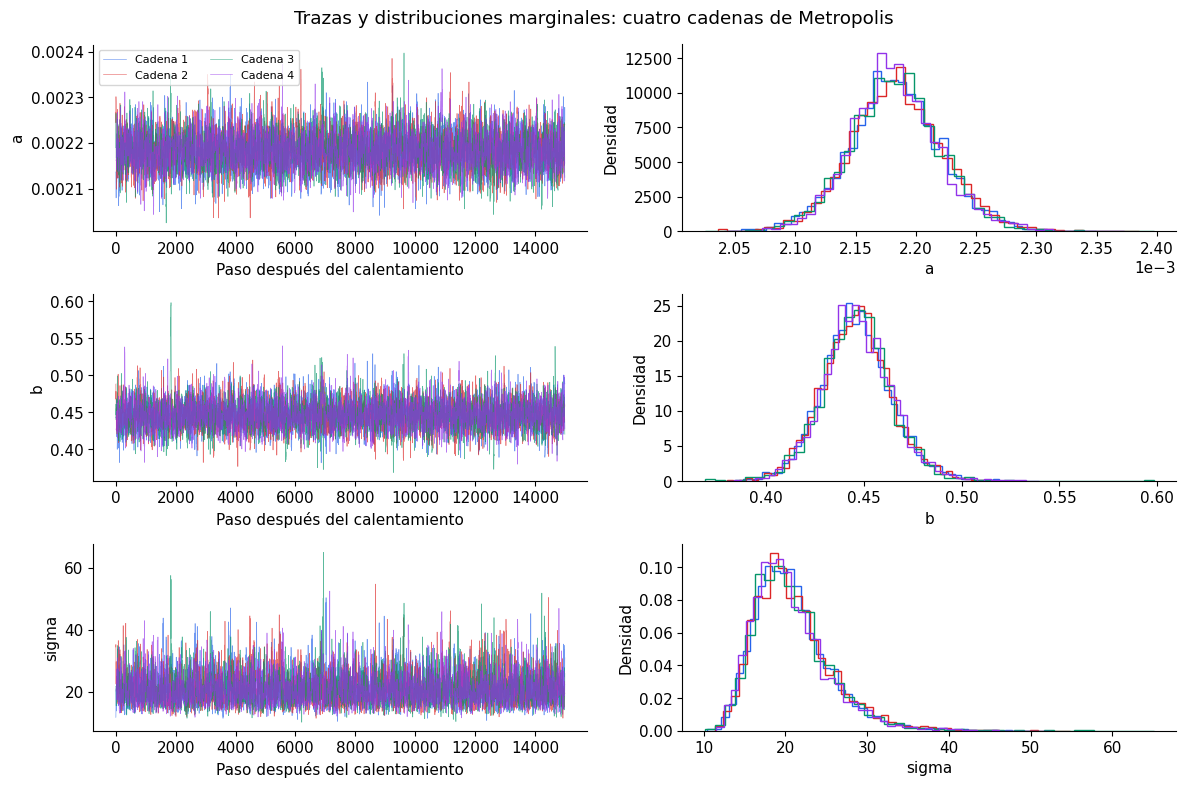

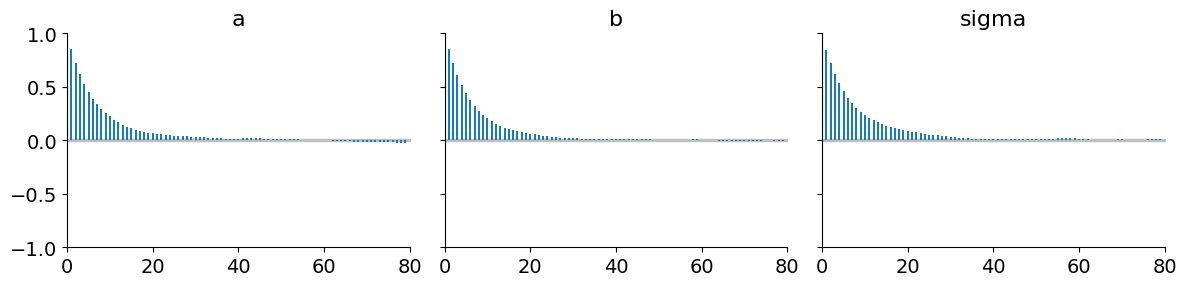

Criterios de diagnóstico satisfechos: True


In [6]:
idata = az.from_dict(posterior={"a": cadenas[:, :, 0], "b": cadenas[:, :, 1],
                                "sigma": cadenas[:, :, 2]})
diagnostico = az.summary(idata, hdi_prob=.95, round_to="none")
display(diagnostico)

fig, axes = plt.subplots(3, 2, figsize=(12, 8))
for k, nombre in enumerate(["a", "b", "sigma"]):
    for c in range(4):
        axes[k, 0].plot(cadenas[c, :, k], color=COLORES[c], lw=.45, alpha=.65, label=f"Cadena {c+1}")
        axes[k, 1].hist(cadenas[c, :, k], bins=45, density=True, histtype="step", color=COLORES[c])
    axes[k, 0].set(ylabel=nombre, xlabel="Paso después del calentamiento")
    axes[k, 1].set(xlabel=nombre, ylabel="Densidad")
axes[0, 1].ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
axes[0, 0].legend(ncol=2, fontsize=8)
fig.suptitle("Trazas y distribuciones marginales: cuatro cadenas de Metropolis")
fig.tight_layout()
plt.show()
az.plot_autocorr(idata, var_names=["a", "b", "sigma"], combined=True, max_lag=80, figsize=(12, 3))
plt.tight_layout()
plt.show()

convergencia_ok = bool((diagnostico.r_hat < 1.01).all()
                      and (diagnostico.ess_bulk > 400).all()
                      and (diagnostico.ess_tail > 400).all())
print("Criterios de diagnóstico satisfechos:", convergencia_ok)
assert convergencia_ok, "Revisar mezcla o aumentar n_muestras antes de interpretar los resultados."


## **6. Estimaciones posteriores y resultados finales**

Se presentan la **mediana posterior** y el intervalo creíble del 95 %, delimitado por los percentiles 2.5 y 97.5. Este intervalo representa la incertidumbre de los parámetros según el modelo y los priors establecidos. A diferencia de este intervalo central, los intervalos HDI calculados con ArviZ pueden presentar pequeñas diferencias.

También se estiman el número reproductivo básico, $\mathcal R_0=aN/b$, y la duración media de la infección, $1/b$. Ambos valores se calculan a partir de cada muestra conjunta de los parámetros para conservar sus posibles correlaciones. Por ello, las medianas individuales no necesariamente corresponden a la combinación de parámetros con mayor probabilidad posterior.

,Límite 2.5%,Mediana,Límite 97.5%
a [alumno^-1 día^-1],0.002110,0.002182,0.002262
b [día^-1],0.412184,0.446161,0.483922
sigma [alumnos],13.894268,19.996300,31.929126
R0 = a*N/b,3.466991,3.731873,4.019178
R efectivo inicial = a*S0/b,3.462447,3.726982,4.013910
Duración infecciosa media [días],2.066447,2.241345,2.426102


### Solución final del ajuste
- **Transmisión a:** 0.0021825 (ICr 95 %: 0.0021097, 0.0022620) alumno⁻¹ día⁻¹.
- **Recuperación b:** 0.44616 (ICr 95 %: 0.41218, 0.48392) día⁻¹.
- **R₀:** 3.732 (ICr 95 %: 3.467, 4.019).
- **Duración media infecciosa:** 2.241 (ICr 95 %: 2.066, 2.426) días.

Los criterios numéricos de diagnóstico se satisficieron para las cadenas ejecutadas.

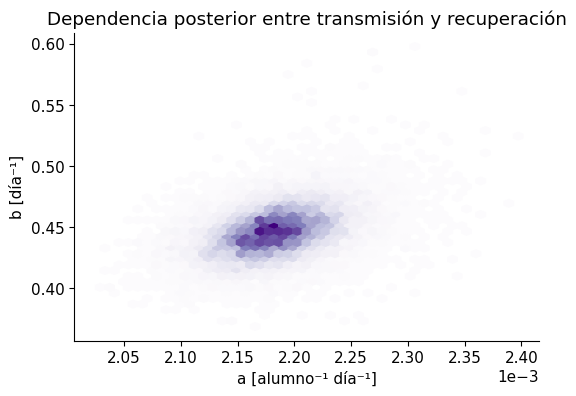

In [8]:
muestras = cadenas.reshape(-1, 3)
valores = {
    "a [alumno^-1 día^-1]": muestras[:, 0],
    "b [día^-1]": muestras[:, 1],
    "sigma [alumnos]": muestras[:, 2],
    "R0 = a*N/b": muestras[:, 0]*N/muestras[:, 1],
    "R efectivo inicial = a*S0/b": muestras[:, 0]*Y0[0]/muestras[:, 1],
    "Duración infecciosa media [días]": 1.0/muestras[:, 1]
}
tabla_final = pd.DataFrame({nombre: np.quantile(v, [.025, .5, .975]) for nombre, v in valores.items()},
                           index=["Límite 2.5%", "Mediana", "Límite 97.5%"]).T
display(tabla_final.style.format("{:.6f}").set_caption("Solución posterior: intervalos centrales del 95 %"))
a_med, b_med, sigma_med = np.median(muestras, axis=0)

def formato_resultado(nombre, cifras=5):
    lo, med, hi = tabla_final.loc[nombre]
    return f"{med:.{cifras}f} (ICr 95 %: {lo:.{cifras}f}, {hi:.{cifras}f})"

display(Markdown(
    "### Solución final del ajuste\n"
    f"- **Transmisión a:** {formato_resultado('a [alumno^-1 día^-1]', 7)} alumno⁻¹ día⁻¹.\n"
    f"- **Recuperación b:** {formato_resultado('b [día^-1]')} día⁻¹.\n"
    f"- **R₀:** {formato_resultado('R0 = a*N/b', 3)}.\n"
    f"- **Duración media infecciosa:** {formato_resultado('Duración infecciosa media [días]', 3)} días.\n\n"
    "Los criterios numéricos de diagnóstico se satisficieron para las cadenas ejecutadas."
))

fig, ax = plt.subplots(figsize=(6, 4))
ax.hexbin(muestras[:, 0], muestras[:, 1], gridsize=45, cmap="Purples", mincnt=1)
ax.set(xlabel="a [alumno⁻¹ día⁻¹]", ylabel="b [día⁻¹]", title="Dependencia posterior entre transmisión y recuperación")
ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
plt.show()


## **7. Ajuste del modelo, incertidumbre y residuos**

La banda azul representa la incertidumbre de la trayectoria estimada de infectados $I(t)$, considerando únicamente la variabilidad de los parámetros. La banda gris incluye, además, el ruido gaussiano para representar la incertidumbre de nuevas observaciones. Ambas corresponden a intervalos puntuales del 95 %, no simultáneos. La aproximación normal puede generar límites negativos en las predicciones, por lo que se mantienen sin modificar para mostrar esta limitación.

Las curvas de susceptibles $S$ y recuperados $R$ son predicciones, ya que sólo se dispone de observaciones de infectados. Finalmente, se comparan los parámetros estimados con los obtenidos mediante el algoritmo genético del artículo: $a\approx0.00205$ y $b\approx0.43552$. Es posible que existan diferencias debido a los distintos métodos de ajuste y al tratamiento de la incertidumbre.

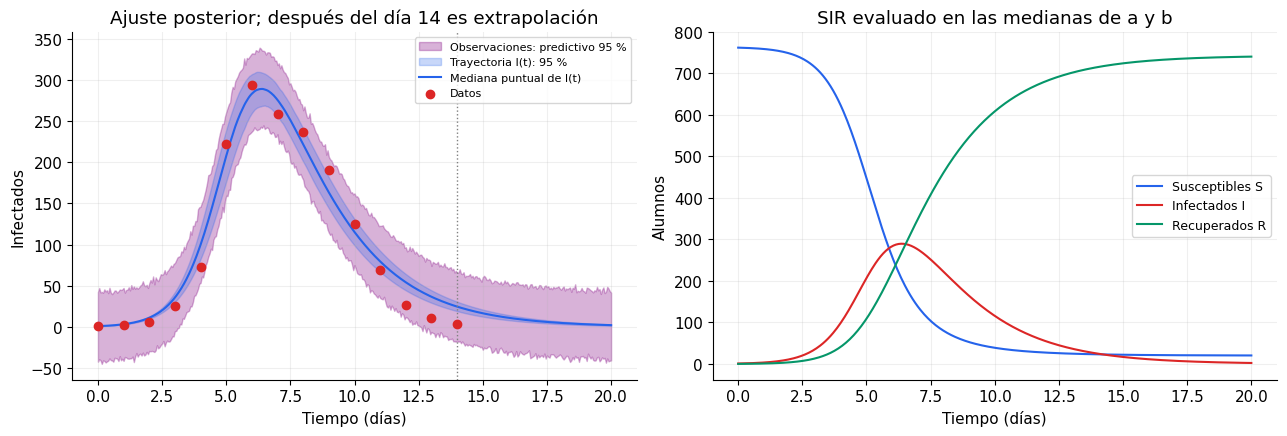

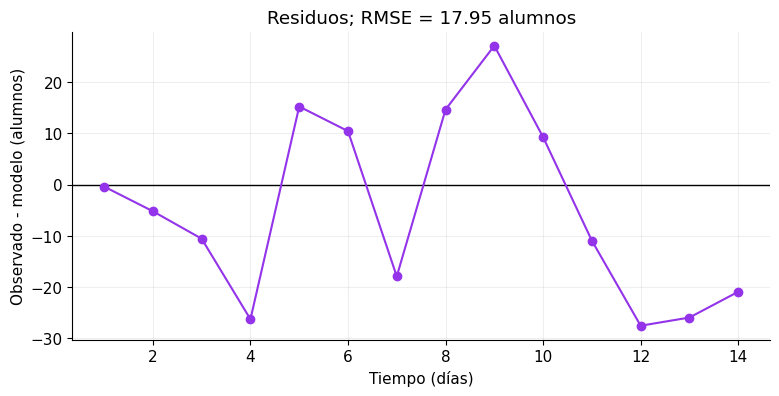

,a,b
Medianas Metropolis (este cuaderno),0.002182,0.446161
Algoritmo genético (artículo SIR),0.002050,0.435520


Correlación posterior a,b: 0.396
P(R efectivo inicial > 1 | datos): 1.0000


**Lectura del ajuste:** RMSE = 17.95 alumnos. Los residuos son negativos en los últimos cuatro días: el SIR ajustado sobreestima los infectados al final del intervalo. Esta estructura invita a revisar la hipótesis de error independiente y de escala constante, aunque la mezcla de las cadenas sea adecuada.

In [11]:
t_fino = np.linspace(0, 20, 401)
sol_med = resolver_sir(a_med, b_med, t_fino)
rng_pred = np.random.default_rng(SEED + 100)
sub = muestras[rng_pred.choice(len(muestras), size=800, replace=False)]
curvas = np.stack([resolver_sir(a, b, t_fino)[:, 1] for a, b, sigma in sub])
bandas_modelo = np.quantile(curvas, [.025, .5, .975], axis=0)
replicas = curvas + rng_pred.normal(size=curvas.shape)*sub[:, 2, None]
bandas_pred = np.quantile(replicas, [.025, .975], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].fill_between(t_fino, *bandas_pred, color="purple", alpha=.3, label="Observaciones: predictivo 95 %")
axes[0].fill_between(t_fino, bandas_modelo[0], bandas_modelo[2], color=COLORES[0], alpha=.25, label="Trayectoria I(t): 95 %")
axes[0].plot(t_fino, bandas_modelo[1], color=COLORES[0], label="Mediana puntual de I(t)")
axes[0].scatter(t_obs, i_obs, color=COLORES[1], zorder=5, label="Datos")
axes[0].axvline(14, color="gray", ls=":", lw=1)
axes[0].set(xlabel="Tiempo (días)", ylabel="Infectados", title="Ajuste posterior; después del día 14 es extrapolación")
axes[0].legend(fontsize=8)
for k, etiqueta in enumerate(["Susceptibles S", "Infectados I", "Recuperados R"]):
    axes[1].plot(t_fino, sol_med[:, k], color=COLORES[k], label=etiqueta)
axes[1].set(xlabel="Tiempo (días)", ylabel="Alumnos", title="SIR evaluado en las medianas de a y b")
axes[1].legend(fontsize=9)
for ax in axes:
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

pred_obs = resolver_sir(a_med, b_med)[:, 1]
residuos_finales = i_fit - pred_obs[1:]
rmse = np.sqrt(np.mean(residuos_finales**2))
fig, ax = plt.subplots()
ax.axhline(0, color="black", lw=1)
ax.plot(t_fit, residuos_finales, "o-", color=COLORES[3])
ax.set(xlabel="Tiempo (días)", ylabel="Observado - modelo (alumnos)", title=f"Residuos; RMSE = {rmse:.2f} alumnos")
ax.grid(alpha=.2)
plt.show()
comparacion = pd.DataFrame({"a": [a_med, .00205], "b": [b_med, .43552]},
                           index=["Medianas Metropolis (este cuaderno)", "Algoritmo genético (artículo SIR)"])
display(comparacion)
print(f"Correlación posterior a,b: {np.corrcoef(muestras[:, 0], muestras[:, 1])[0, 1]:.3f}")
print(f"P(R efectivo inicial > 1 | datos): {np.mean(valores['R efectivo inicial = a*S0/b'] > 1):.4f}")

display(Markdown(f"**Lectura del ajuste:** RMSE = {rmse:.2f} alumnos. Los residuos son negativos en los últimos cuatro días: el SIR ajustado sobreestima los infectados al final del intervalo. Esta estructura invita a revisar la hipótesis de error independiente y de escala constante, aunque la mezcla de las cadenas sea adecuada."))


## **8. Validación numérica independiente**

Se verifica la precisión de la integración comparando LSODA con el método DOP853 de `solve_ivp`, utilizando tolerancias más estrictas y las medianas posteriores de los parámetros. También se comprueba que la población total se conserve y que las variables sean no negativas. Esta revisión permite evaluar la consistencia numérica del ajuste, pero no garantiza que los supuestos epidemiológicos sean correctos.

In [ ]:
ref = solve_ivp(lambda t, y: sir_derivadas(y, t, a_med, b_med),
                (0., float(t_obs[-1])), Y0, t_eval=t_obs,
                method="DOP853", rtol=1e-10, atol=1e-10)
if not ref.success:
    raise RuntimeError(ref.message)
sol_lsoda = resolver_sir(a_med, b_med)
error_integracion = np.max(np.abs(ref.y.T - sol_lsoda))
error_poblacion = np.max(np.abs(sol_lsoda.sum(axis=1) - N))
assert error_integracion < 1e-3, "Revisar tolerancias del integrador."
assert error_poblacion < 1e-3
assert sol_lsoda.min() >= -1e-4
print(f"Diferencia máxima LSODA/DOP853: {error_integracion:.3e} alumnos")
print(f"Error máximo en S+I+R=N: {error_poblacion:.3e} alumnos")
print("Verificaciones numéricas satisfechas.")


Diferencia máxima LSODA/DOP853: 5.069e-05 alumnos
Error máximo en S+I+R=N: 6.821e-13 alumnos
Verificaciones numéricas satisfechas.


## **9. Interpretación y limitaciones**

El modelo permite estimar los parámetros de una epidemia a partir de la evolución de los infectados. El análisis conjunto muestra que una mayor tasa de recuperación puede compensarse parcialmente con una mayor transmisión. Además, un número reproductivo inicial superior a uno indica que la infección tiende a crecer al comienzo.

El análisis de los residuos permite evaluar si el modelo representa adecuadamente los datos. Si presentan patrones temporales o errores mayores cerca del pico de contagios, sería necesario revisar el supuesto de errores independientes y de varianza constante. Las 14 observaciones disponibles son insuficientes para confirmar estos supuestos.

Los intervalos estimados no consideran posibles errores en las condiciones iniciales, subregistro de casos, contactos heterogéneos ni cambios en las tasas de transmisión y recuperación. Por ello, las predicciones de susceptibles y recuperados, así como las extrapolaciones posteriores al día 14, dependen de los supuestos del modelo SIR. Como mejora, podría utilizarse un modelo de conteos con sobredispersión y evaluar la sensibilidad a los priors y las condiciones iniciales. Estos resultados tienen fines académicos y no constituyen recomendaciones sanitarias.